# Lightweight Classifiers — **Tier B: Davide Chicco's clinical cohorts** + **meta-analysis across all datasets**

**En français.** Même protocole que la réplication (excès de patients oubliés au-delà du hasard du ré-entraînement), appliqué aux cohortes cliniques publiques des articles de Davide. Principe : **peu de tests, beaucoup de datasets**. À la fin, une **méta-analyse à effets aléatoires** combine tous les datasets disponibles (réplication, extension, Tier B).

**Règles fixées avant de voir les résultats**
| Règle | Définition |
|---|---|
| Inclusion | issue binaire ; ≥ 250 patients ; ≥ 50 patients dans la classe minoritaire ; variables tabulaires |
| Cible | issue clinique défavorable (décès, maladie) = classe positive |
| Anti-fuite | exclusion des identifiants, dates, durées de suivi et de toute autre variable d'issue |
| Protocole | 50 partitions, 3 copies ré-entraînées, RF 128→16, GBM 400→100, budgets 10 % et 20 %, IC de Nadeau–Bengio |
| Méta-analyse | DerSimonian–Laird sur l'excès de patients oubliés pour 100 événements, budget 10 % |

⚠️ **Les cibles sont détectées automatiquement quand elles ne sont pas encore fixées.** Le fichier `TARGETS_USED.md` liste, pour chaque dataset, la cible, la classe positive et les variables utilisées ou exclues : il doit être vérifié avant que ces résultats entrent dans l'article.

**Run (Colab):** *Runtime → Run all*. `QUICK_TEST = True` first (minutes), then `False`.

### 1 · Configuration et Drive

In [10]:
import os, sys, io, json, re, time, zipfile, tarfile, hashlib, pickle, platform, warnings, gc, subprocess, urllib.request
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd, scipy, sklearn
from scipy import stats
warnings.filterwarnings('ignore')

# ======================= USER CONFIGURATION =======================
QUICK_TEST    = False
RUN_NAME      = 'EXCESS_TIERB_DAVIDE_20261110_R3'
N_SPLITS      = 50
N_RETRAIN     = 3
ALERT_BUDGETS = [0.10, 0.20]
RF_PARENT, RF_SMALL   = 128, 16
GBM_PARENT, GBM_SMALL = 400, 100
BOOTSTRAP_DRAWS = 500
MIN_PATIENTS, MIN_MINORITY = 250, 50
OTHER_RUNS = ['EXCESS_REPLICATION_20261110_R1', 'EXCESS_EXTENSION_20261110_R2']   # pooled in the meta-analysis
# ==================================================================
if QUICK_TEST:
    N_SPLITS, N_RETRAIN = 2, 2
    RF_PARENT, RF_SMALL, GBM_PARENT, GBM_SMALL, BOOTSTRAP_DRAWS = 32, 8, 100, 25, 100
    RUN_NAME += '_QUICKTEST'; OTHER_RUNS = [r + '_QUICKTEST' for r in OTHER_RUNS]
PRIMARY_BUDGET = ALERT_BUDGETS[0]

try:
    from google.colab import drive
    drive.mount('/content/drive'); PROJECT_HOME = Path('/content/drive/MyDrive/CHICCO_MEGA_RESEARCH'); MODE = 'google_colab_drive'
except ImportError:
    PROJECT_HOME = Path(os.environ['CHICCO_LOCAL_DRIVE_ROOT']); MODE = 'explicit_local_drive_mirror'
DAV = PROJECT_HOME / 'data' / 'raw' / 'davide'; DAV.mkdir(parents=True, exist_ok=True)
OUT = PROJECT_HOME / 'results' / RUN_NAME
for d in [OUT, OUT / 'splits', OUT / 'figures']: d.mkdir(parents=True, exist_ok=True)
for pkg in ['openpyxl', 'xlrd', 'pyreadr', 'ucimlrepo']:
    try: __import__(pkg)
    except ImportError: subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', pkg], check=False)
try:
    import lightgbm as lgb; GBM_BACKEND = 'lightgbm ' + lgb.__version__
except ImportError:
    lgb = None; GBM_BACKEND = 'sklearn HistGradientBoosting ' + sklearn.__version__
try:
    from IPython.display import display
except ImportError:
    display = lambda x: print(x.to_string() if hasattr(x, 'to_string') else x)
UA = {'User-Agent': 'Mozilla/5.0 (research notebook; Chicco-Ganmati project)'}
def http(url, data=None, headers=None):
    req = urllib.request.Request(url, data=data, headers=dict(UA, **(headers or {})))
    with urllib.request.urlopen(req, timeout=180) as r: return r.read()
print('MODE:', MODE, '| GBM:', GBM_BACKEND, '| results ->', OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MODE: google_colab_drive | GBM: lightgbm 4.6.0 | results -> /content/drive/MyDrive/CHICCO_MEGA_RESEARCH/results/EXCESS_TIERB_DAVIDE_20261110_R3


### 2 · Téléchargement (réutilise les fichiers déjà présents dans `data/raw/davide/`)

In [11]:
SOURCES = {
  'cardiac_arrest_spain':      ('figshare_id', 4876247),
  'depression_heart_failure':  ('figshare_id', 3916224),
  'lung_cancer_icu':           ('figshare_id', 7713893),
  'clinical_data_14201600':    ('figshare_id', 14201600),
  'sepsis_icu_90day':          ('figshare_id', 28873667),
  'sepsis_sirs':               ('figshare_title', 'C-Reactive Protein and Hemogram Parameters for the Non-Sepsis Systemic Inflammatory Response Syndrome and Sepsis: What Do They Mean?'),
  'ckd_uae':                   ('figshare_title', 'Chronic kidney disease in patients at high risk of cardiovascular disease in the United Arab Emirates: A population-based study'),
  'mesothelioma':              ('uci', 351),
  'heart_failure_chicco':      ('uci', 519),
  'neuroblastoma_shanghai':    ('manual', 'PeerJ 6:e5665 supplemental files, put them in data/raw/davide/neuroblastoma_shanghai/'),
}

def figshare_article(aid):
    return json.loads(http(f'https://api.figshare.com/v2/articles/{aid}'))

def figshare_search(title):
    body = json.dumps({'search_for': f'"{title}"', 'page_size': 20}).encode()
    hits = json.loads(http('https://api.figshare.com/v2/articles/search', data=body, headers={'Content-Type': 'application/json'}))
    norm = lambda s: re.sub(r'[^a-z0-9]', '', s.lower())
    return [h for h in hits if norm(title)[:60] in norm(h.get('title', ''))] or hits[:3]

def save_files(art, folder):
    folder.mkdir(parents=True, exist_ok=True); got = []
    meta = {k: art.get(k) for k in ('id', 'title', 'doi', 'url_public_html', 'resource_doi', 'resource_title', 'license')}
    (folder / f"figshare_{art['id']}.json").write_text(json.dumps(meta, indent=2, default=str))
    for f in art.get('files', []):
        dest = folder / f['name']
        if not dest.exists():
            dest.write_bytes(http(f['download_url']))
        got.append(dest.name)
    return got

def fetch(name, kind, ref):
    folder = DAV / name
    if folder.exists() and any(p.suffix.lower() in {'.csv', '.xlsx', '.xls', '.txt', '.tsv', '.rda', '.rdata', '.sav', '.dta'} for p in folder.rglob('*')):
        return 'already present'
    if kind == 'figshare_id':
        return save_files(figshare_article(ref), folder)
    if kind == 'figshare_title':
        got = []
        for h in figshare_search(ref):
            got += save_files(figshare_article(h['id']), folder)
        return got or 'no figshare match'
    if kind == 'uci':
        from ucimlrepo import fetch_ucirepo
        d = fetch_ucirepo(id=ref); folder.mkdir(parents=True, exist_ok=True)
        df = d.data.original if getattr(d.data, 'original', None) is not None else pd.concat([d.data.features, d.data.targets], axis=1)
        df.to_csv(folder / f'uci_{ref}.csv', index=False); return [f'uci_{ref}.csv']
    if kind == 'cran':
        idx = http(f'https://cloud.r-project.org/web/packages/{ref}/index.html').decode('utf-8', 'ignore')
        tgz = re.search(rf'{ref}_[0-9.\-]+\.tar\.gz', idx).group(0)
        blob = http(f'https://cloud.r-project.org/src/contrib/{tgz}'); folder.mkdir(parents=True, exist_ok=True)
        with tarfile.open(fileobj=io.BytesIO(blob)) as t:
            for m in t.getmembers():
                if m.isfile() and m.name.lower().endswith(('.rda', '.rdata', '.csv')):
                    (folder / Path(m.name).name).write_bytes(t.extractfile(m).read())
        return [p.name for p in folder.iterdir()]


fetch_status = {}
for name, (kind, ref) in SOURCES.items():
    if kind == 'manual':
        (DAV / name).mkdir(parents=True, exist_ok=True); fetch_status[name] = 'manual: ' + ref
    else:
        try: fetch_status[name] = fetch(name, kind, ref)
        except Exception as e: fetch_status[name] = f'FAILED: {type(e).__name__}: {e}'
    print(f'{name:26s} -> {fetch_status[name]}')

cardiac_arrest_spain       -> already present
depression_heart_failure   -> already present
lung_cancer_icu            -> already present
clinical_data_14201600     -> already present
sepsis_icu_90day           -> already present
sepsis_sirs                -> already present
ckd_uae                    -> already present
mesothelioma               -> FAILED: DatasetNotFoundError: "Mesothelioma's disease data set " dataset (id=351) exists in the repository, but is not available for import. Please select a dataset from this list: https://archive.ics.uci.edu/datasets?skip=0&take=10&sort=desc&orderBy=NumHits&search=&Python=true
heart_failure_chicco       -> already present
neuroblastoma_shanghai     -> manual: PeerJ 6:e5665 supplemental files, put them in data/raw/davide/neuroblastoma_shanghai/


### 3 · Définition des cibles (à vérifier) et contrôle anti-fuite
`DATASET_SPECS` fixe la cible quand elle est connue. Sinon, la cible est **proposée automatiquement** parmi les colonnes binaires dont le nom évoque l'issue (décès, mortalité, exitus, classe…). Toutes les décisions sont écrites dans `TARGETS_USED.md`.

In [12]:
def read_tables(p):
    s = p.suffix.lower()
    try:
        if s in {'.xlsx', '.xls'}:
            return {f'{p.name}::{k}': v for k, v in pd.read_excel(p, sheet_name=None).items()}
        if s in {'.csv', '.txt', '.tsv'}:
            return {p.name: pd.read_csv(p, sep=None, engine='python')}
        if s in {'.rda', '.rdata'}:
            import pyreadr
            return {f'{p.name}::{k}': v for k, v in pyreadr.read_r(str(p)).items()}
        if s == '.sav': return {p.name: pd.read_spss(p)}
        if s == '.dta': return {p.name: pd.read_stata(p)}
        if s == '.zip':
            out = {}
            with zipfile.ZipFile(p) as z:
                z.extractall(p.parent / (p.stem + '_unzipped'))
            for q in (p.parent / (p.stem + '_unzipped')).rglob('*'):
                if q.is_file(): out.update(read_tables(q))
            return out
    except Exception as e:
        print('  cannot read', p.name, '-', type(e).__name__, e)
    return {}


DATASET_SPECS = {   # verified 10 Nov 2026 from TARGETS_USED.md of the quick run
  # target column, positive (adverse) value, drop = extra exclusions, keep = override the leak guard, use = explicit predictor list
  'cardiac_arrest_spain': dict(target='Exitus', positive=1, keep=['Functional_status', 'Time_min'],
                               note='death before hospital arrival (Requena-Morales 2017); prior functional status and arrest-to-EMS time are pre-outcome predictors used in the original article'),
  'depression_heart_failure': dict(target='Death (1=Yes, 0=No)', positive=1, drop=['Hospitalized (1=Yes, 0=No)'],
                               note='2-year death (Jani 2016); hospitalization during follow-up is a second outcome: excluded'),
  'lung_cancer_icu': dict(target='Hospital_death', positive=1,
                          use=['sex', 'age', 'Pre_PS', 'PoorPS', 'Histology_coding', 'Stage', 'Distatntmets', 'Surgery', 'WBRT', 'pallRT',
                               'prev_op', 'prev_rtx', 'prev_gks', 'prev_wbrt', 'prev_ctx', 'prev_ccrt', 'line', 'Refractory', 'Txoff', 'NewlyDx',
                               'cancer_status', 'Underlying_CV', 'Underlying_stroke', 'underlying_pulmo', 'pulmocomorbid', 'ILD', 'Underlying_DM',
                               'Underlying_etc', 'other_malignancy', 'smk_hx', 'Pneumonia', 'Sepsis', 'respfailure', 'hemodynamic', 'AKI',
                               'neurology', 'cardiovasc', 'prevCPR', 'Planned', 'preICUDNR', 'admission_via', 'PrevICUadm', 'Intensivist', 'post2011',
                               'neutropenia', 'ANC', 'WBC', 'anemia', 'Hb', 'thrombocytopenia', 'PLT', 'hypoalbuminemia', 'Albumin', 'BUN', 'Cr',
                               'highCr', 'Na', 'K', 'PT_percent', 'aPTT', 'procalcitonin', 'PaO2FiO2', 'SAPS_II', 'APACH_II', 'SOFA_D1'],
                          note='hospital death (Song 2019, primary outcome); only variables known at ICU admission (no ICU treatments, no post-ICU or discharge variables)'),
  'sepsis_sirs':     dict(target='Mortality', positive=1, note='ICU mortality (Gucyetmez & Atalan 2016)'),
  'ckd_uae':         dict(target='EventCKD35', positive=1, drop=['StudyID'], note='CKD stage 3-5 event (Al-Shamsi 2018); StudyID is an identifier'),
  'heart_failure_chicco': dict(target='DEATH_EVENT', positive=1, drop=['time'], note='death (Chicco & Jurman 2020); time = follow-up length (outcome-related): excluded'),
  'mesothelioma':    dict(target=None, positive=None, drop=['diagnosis method'], note='diagnosis method can reveal the class: excluded'),
}
TARGET_WORDS = ['death', 'dead', 'died', 'deceas', 'mortal', 'exitus', 'fallec', 'muert', 'surviv', 'outcome', 'class', 'status', 'event', 'sepsis', 'ckd', 'diagnos']
LEAK = re.compile(r'(time|days?\b|month|follow|^fu_|los\b|length|stay|death|dead|died|deceas|mortal|surviv|exitus|outcome|discharge|readmi|event|censor|date|_os\b|^os\b|pfs)', re.I)
IDLIKE = re.compile(r'(^id$|_id$|^id_|studyid|serial|patient|record|^n$|^no\.?$|^nr|number|code$)', re.I)
ADVERSE = re.compile(r'(dead|death|died|deceas|exitus|fallec|muert|^yes$|^y$|^s[ií]$|sepsis|ckd|mesothel|positive|^true$)', re.I)
ALIVE_NAME = re.compile(r'(alive|surviv)', re.I)

def choose_table(name, tables, spec):
    items = [(k, v) for k, v in tables.items() if isinstance(v, pd.DataFrame) and v.shape[0] >= 20]
    if spec.get('table'): items = [(k, v) for k, v in items if spec['table'] in k]
    if not items: return None, None
    return max(items, key=lambda kv: kv[1].shape[0] * kv[1].shape[1])

def auto_target(df):
    best = None
    for rank, w in enumerate(TARGET_WORDS):
        for c in df.columns:
            if w in str(c).lower() and df[c].nunique(dropna=True) == 2:
                return c
    return best

def positive_value(col, values):
    vals = list(values)
    num = pd.to_numeric(pd.Series(vals), errors='coerce')
    if num.notna().all() and set(num.astype(float)) == {0.0, 1.0}:
        return vals[list(num.astype(float)).index(0.0 if ALIVE_NAME.search(str(col)) else 1.0)], 'numeric 0/1 (1 = event unless the name says alive/survival)'
    hits = [v for v in vals if ADVERSE.search(str(v).strip())]
    if len(hits) == 1: return hits[0], 'value name indicates the adverse outcome'
    return None, 'UNCLEAR'

def build_dataset(name):
    spec = DATASET_SPECS.get(name, {})
    files = [p for p in (DAV / name).rglob('*') if p.is_file() and not p.name.startswith('figshare_')]
    tables = {}
    for p in files: tables.update(read_tables(p))
    key, df = choose_table(name, tables, spec)
    if df is None: return None, dict(dataset=name, status='no readable table')
    df = df.copy(); df.columns = [str(c).strip() for c in df.columns]
    df = df.dropna(axis=1, how='all').dropna(axis=0, how='all')
    lower = {c.lower(): c for c in df.columns}
    target = spec.get('target'); target = lower.get(str(target).lower(), target) if target else auto_target(df)
    if target is None or target not in df.columns:
        return None, dict(dataset=name, table=key, status='no target found', columns=list(df.columns))
    y_raw = df[target]; ok = y_raw.notna(); vals = y_raw[ok].unique()
    if len(vals) != 2: return None, dict(dataset=name, table=key, target=target, status=f'target has {len(vals)} values')
    if spec.get('positive') is not None: pos, why = spec['positive'], 'fixed in DATASET_SPECS'
    else: pos, why = positive_value(target, vals)
    if pos is None:
        counts = y_raw[ok].value_counts(); pos, why = counts.index[-1], 'UNCLEAR -> minority class used (CHECK)'
    num = pd.to_numeric(y_raw[ok], errors='coerce'); pnum = pd.to_numeric(pd.Series([pos]), errors='coerce').iloc[0]
    if num.notna().all() and pd.notna(pnum):
        y = (num.astype(float) == float(pnum)).astype(int).to_numpy()
    else:
        y = (y_raw[ok].astype(str).str.strip() == str(pos).strip()).astype(int).to_numpy()
    X = df.loc[ok].drop(columns=[target]).reset_index(drop=True)
    dropped = {}
    if spec.get('use'):
        missing = [c for c in spec['use'] if c not in X.columns]
        if missing: print(f'  {name}: predictors not found (skipped): {missing}')
        dropped.update({c: 'not in pre-declared predictor list' for c in X.columns if c not in spec['use']})
        X = X[[c for c in spec['use'] if c in X.columns]]
    keep = [k.lower() for k in spec.get('keep', [])]
    for c in list(X.columns):
        reason = None
        if c.lower() in keep and X[c].nunique(dropna=True) > 1: continue
        if c in spec.get('drop', []) or c.lower() in [d.lower() for d in spec.get('drop', [])]: reason = 'specified'
        elif LEAK.search(c): reason = 'outcome/time-related name'
        elif IDLIKE.search(c) and X[c].nunique() > 0.9 * len(X): reason = 'identifier'
        elif pd.api.types.is_datetime64_any_dtype(X[c]): reason = 'date'
        elif X[c].nunique(dropna=True) <= 1: reason = 'constant'
        elif not pd.api.types.is_numeric_dtype(X[c]) and X[c].nunique() > 0.5 * len(X): reason = 'free text / identifier'
        if reason: dropped[c] = reason; X = X.drop(columns=c)
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]):
            num = pd.to_numeric(X[c], errors='coerce')
            if num.notna().mean() > 0.95 and X[c].notna().mean() > 0: X[c] = num
            else: X[c] = X[c].astype('object').where(X[c].notna(), 'Missing').astype(str)
    n, ev = len(y), int(y.sum()); minority = min(ev, n - ev)
    status = 'included' if (n >= MIN_PATIENTS and minority >= MIN_MINORITY and X.shape[1] >= 2) else \
             f'excluded (n={n}, minority={minority}, features={X.shape[1]})'
    info = dict(dataset=name, table=key, target=target, positive=str(pos), positive_rule=why, n=n, events=ev,
                prevalence=round(ev / n, 4), features_used=list(X.columns), features_dropped=dropped, status=status,
                note=spec.get('note', ''))
    groups = np.array([f'{name}_{i}' for i in range(n)])
    return ((X, y, groups, dict(dataset=name, task=f'{target} = {pos}', n=n, events=ev, prevalence=round(ev / n, 4),
                                n_groups=n, group='one row per patient')) if status == 'included' else None), info

DATA, REPORT = {}, []
for name in SOURCES:
    try:
        d, info = build_dataset(name)
    except Exception as e:
        d, info = None, dict(dataset=name, status=f'error: {type(e).__name__}: {e}')
    REPORT.append(info)
    if d is not None: DATA[name] = d
    print(f"{name:26s} {info.get('status')}  target={info.get('target')}  positive={info.get('positive')}  "
          f"n={info.get('n')} events={info.get('events')}  rule={info.get('positive_rule')}")
lines = ['# Targets used (VERIFY before using results in the paper)\n']
for r in REPORT:
    lines.append(f"## {r['dataset']} — {r.get('status')}\n" + '\n'.join(f'- {k}: {v}' for k, v in r.items() if k not in ('dataset', 'status')) + '\n')
(OUT / 'TARGETS_USED.md').write_text('\n'.join(lines))
DATASETS = list(DATA)
CONFIG = dict(run_name=RUN_NAME, datasets=DATASETS, n_splits=N_SPLITS, n_retrain=N_RETRAIN, alert_budgets=ALERT_BUDGETS,
              rf_parent=RF_PARENT, rf_small=RF_SMALL, gbm_parent=GBM_PARENT, gbm_small=GBM_SMALL, bootstrap=BOOTSTRAP_DRAWS,
              gbm_backend=GBM_BACKEND.split()[0], targets={r['dataset']: (r.get('target'), r.get('positive')) for r in REPORT if r['dataset'] in DATA},
              protocol_version='2026-11-10_tierB_v1')
SIGNATURE = hashlib.sha256(json.dumps(CONFIG, sort_keys=True, default=str).encode()).hexdigest()[:16]
(OUT / 'PROTOCOL.json').write_text(json.dumps(CONFIG, indent=2, default=str))
print('\nINCLUDED:', DATASETS, '| signature', SIGNATURE, '\nCheck:', OUT / 'TARGETS_USED.md')

cardiac_arrest_spain       included  target=Exitus  positive=1  n=422 events=337  rule=fixed in DATASET_SPECS
depression_heart_failure   included  target=Death (1=Yes, 0=No)  positive=1  n=425 events=99  rule=fixed in DATASET_SPECS
lung_cancer_icu            included  target=Hospital_death  positive=1  n=264 events=160  rule=fixed in DATASET_SPECS
clinical_data_14201600     excluded (n=60, minority=24, features=5)  target=OS status (1=deceased, 0=living)  positive=1  n=60 events=36  rule=numeric 0/1 (1 = event unless the name says alive/survival)
sepsis_icu_90day           excluded (n=123, minority=44, features=12)  target=Survival_Status  positive=2  n=123 events=44  rule=UNCLEAR -> minority class used (CHECK)
sepsis_sirs                included  target=Mortality  positive=1  n=1257 events=129  rule=fixed in DATASET_SPECS
ckd_uae                    included  target=EventCKD35  positive=1  n=491 events=56  rule=fixed in DATASET_SPECS
mesothelioma               no readable table  target

### 4 · Modèles et mesures (identiques à la réplication)

In [13]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

def grouped_split(y, groups, seed):
    idx = np.arange(len(y))
    dev, test = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=seed).split(idx, y, groups))
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=0.1875, random_state=seed + 1).split(dev, y[dev], groups[dev]))
    train, val = dev[a], dev[b]
    for p, q in [(train, val), (train, test), (val, test)]:
        assert set(groups[p]).isdisjoint(set(groups[q])), 'PATIENT LEAKAGE'
    for part in (train, val, test):
        assert len(np.unique(y[part])) == 2, 'a partition has a single class'
    return train, val, test

def make_preprocessor(X):
    num = X.select_dtypes(include='number').columns.tolist()
    cat = [c for c in X.columns if c not in num]
    tr = []
    if num:
        tr.append(('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                                    ('sc', StandardScaler())]), num))
    if cat:
        tr.append(('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                                    ('oh', OneHotEncoder(handle_unknown='ignore', min_frequency=0.002,
                                                         sparse_output=False))]), cat))
    return ColumnTransformer(tr, sparse_threshold=0)

def fit_rf(Xt, yt, n_trees, seed):
    return RandomForestClassifier(n_estimators=n_trees, min_samples_leaf=2, max_features='sqrt',
                                  n_jobs=-1, random_state=seed).fit(Xt, yt)

def tree_probabilities(rf, X):
    # One row per tree; the forest score is exactly the mean over rows.
    return np.stack([t.predict_proba(X)[:, 1] for t in rf.estimators_]).astype(np.float32)

def fit_gbm(Xt, yt, n_iter, seed, small=False):
    leaves = 7 if small else 31
    if lgb is not None:
        m = lgb.LGBMClassifier(n_estimators=n_iter, learning_rate=0.05, num_leaves=leaves,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               min_child_samples=50, random_state=seed, n_jobs=-1, verbose=-1)
    else:
        m = HistGradientBoostingClassifier(max_iter=n_iter, learning_rate=0.05, max_leaf_nodes=leaves,
                                           min_samples_leaf=50, max_features=0.8, early_stopping=False,
                                           random_state=seed)
    return m.fit(Xt, yt)

def gbm_scores(m, X, n_iter=None):
    if lgb is not None:
        return m.predict_proba(X, num_iteration=n_iter)[:, 1]
    if n_iter is None:
        return m.predict_proba(X)[:, 1]
    for i, p in enumerate(m.staged_predict_proba(X), start=1):
        if i == n_iter: return p[:, 1]
    raise ValueError('n_iter larger than fitted iterations')

def fit_lr(Xt, yt):
    return LogisticRegression(solver='liblinear', max_iter=2000).fit(Xt, yt)

def serialized_bytes(obj):
    return len(pickle.dumps(obj, protocol=pickle.HIGHEST_PROTOCOL))
SPLITTERS = {}

In [14]:
from scipy.stats import norm

def counts(y, alert):
    y = y.astype(bool); a = alert.astype(bool)
    return dict(TP=int((y & a).sum()), FP=int((~y & a).sum()), FN=int((y & ~a).sum()), TN=int((~y & ~a).sum()))

def mcc_from(tp, tn, fp, fn):
    tp, tn, fp, fn = [np.asarray(v, float) for v in (tp, tn, fp, fn)]
    den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return np.divide(tp * tn - fp * fn, den, out=np.zeros_like(den), where=den > 0)

def calibration_slope(y, p):
    pc = np.clip(p, 1e-3, 1 - 1e-3)   # forests give many exact 0/1 scores; slope is indicative only for RF
    z = np.log(pc / (1 - pc)).reshape(-1, 1)
    try:
        return float(LogisticRegression(C=1e6, max_iter=1000).fit(z, y).coef_[0, 0])
    except Exception:
        return float('nan')

def model_metrics(y, p, alert):
    c = counts(y, alert)
    sens = c['TP'] / max(1, c['TP'] + c['FN']); spec = c['TN'] / max(1, c['TN'] + c['FP'])
    return dict(**c, mcc=float(mcc_from(c['TP'], c['TN'], c['FP'], c['FN'])), sensitivity=sens, specificity=spec,
                alert_rate=float(alert.mean()), auroc=float(roc_auc_score(y, p)),
                auprc=float(average_precision_score(y, p)), brier=float(brier_score_loss(y, p)),
                calibration_slope=calibration_slope(y, p), observed_over_expected=float(y.mean() / max(1e-9, p.mean())))

def change_vectors(y, ref, cand):
    y = y.astype(bool); r = ref.astype(bool); c = cand.astype(bool)
    return dict(newly_missed=(y & r & ~c), recovered=(y & ~r & c),
                new_false_alarms=(~y & ~r & c), removed_false_alarms=(~y & r & ~c))

def excess_comparison(y, groups_inv, n_groups, boot_idx, dec, ref, cand, retrains):
    # Candidate change vs the parent, minus the average change produced by retraining alone.
    cv = change_vectors(y, dec[ref], dec[cand])
    rv = [change_vectors(y, dec[ref], dec[r]) for r in retrains]
    out = {}
    for k in cv:
        out[f'{k}_candidate'] = int(cv[k].sum())
        out[f'{k}_retrain_mean'] = float(np.mean([v[k].sum() for v in rv]))
        out[f'excess_{k}'] = out[f'{k}_candidate'] - out[f'{k}_retrain_mean']
    net_c = cv['newly_missed'].astype(float) - cv['recovered']
    net_r = np.mean([v['newly_missed'].astype(float) - v['recovered'] for v in rv], axis=0)
    per_patient = {'excess_newly_missed': cv['newly_missed'] - np.mean([v['newly_missed'] for v in rv], axis=0),
                   'excess_net_tp_lost': net_c - net_r}
    out['excess_net_tp_lost'] = float(per_patient['excess_net_tp_lost'].sum())
    for k, vec in per_patient.items():
        s = np.bincount(groups_inv, weights=vec, minlength=n_groups)
        b = s[boot_idx].sum(axis=1)
        out[f'{k}_boot_low'], out[f'{k}_boot_high'] = [float(v) for v in np.percentile(b, [2.5, 97.5])]
    mc = lambda a: float(mcc_from(**{k.lower(): v for k, v in counts(y, a).items()}))
    out['mcc_candidate'] = mc(dec[cand]); out['mcc_parent'] = mc(dec[ref])
    out['mcc_retrain_mean'] = float(np.mean([mc(dec[r]) for r in retrains]))
    out['excess_delta_mcc'] = out['mcc_candidate'] - out['mcc_retrain_mean']
    return out

def thinning_mechanism(y, tree_p, thr_parent, thr_thin, k, alert_parent, alert_thin):
    M = tree_p.shape[0]
    mu = tree_p.mean(0).astype(float); var = tree_p.var(0).astype(float)
    sd = np.sqrt(var / k * (M - k) / max(1, M - 1))
    with np.errstate(divide='ignore', invalid='ignore'):
        p_alert = np.where(sd > 0, 1 - norm.cdf((thr_thin - mu) / np.where(sd > 0, sd, 1)), (mu >= thr_thin).astype(float))
    p_change = np.where(alert_parent, 1 - p_alert, p_alert)
    obs_change = alert_parent != alert_thin
    pos_alerted = (y == 1) & alert_parent
    margin = mu[pos_alerted] - thr_parent
    q = np.quantile(margin, [0.25, 0.5, 0.75]) if pos_alerted.sum() >= 8 else np.array([0, 0, 0])
    quart = np.digitize(margin, q)
    lost = ~alert_thin[pos_alerted]
    return dict(expected_newly_missed=float((1 - p_alert)[pos_alerted].sum()),
                observed_newly_missed=int(lost.sum()),
                expected_changes=float(p_change.sum()), observed_changes=int(obs_change.sum()),
                auroc_predicting_changes=float(roc_auc_score(obs_change, p_change)) if 0 < obs_change.sum() < len(obs_change) else float('nan'),
                margin_quartile_n=[int((quart == i).sum()) for i in range(4)],
                margin_quartile_lost_thinned=[int(lost[quart == i].sum()) for i in range(4)],
                _quart=quart, _pos_alerted=pos_alerted)

### 5 · Analyse par dataset (checkpoint Drive après chaque partition)

In [15]:
def run_split(name, s):
    path = OUT / 'splits' / f'{name}_split{s:02d}.json'
    if path.exists():
        try:
            if json.loads(path.read_text()).get('signature') == SIGNATURE:
                return 'resumed'
        except Exception:
            pass
    t0 = time.time()
    X, y, groups, meta = DATA[name]
    seed = 1000 + 37 * s
    tr, va, te = SPLITTERS.get(name, grouped_split)(y, groups, seed)
    prep = make_preprocessor(X.iloc[tr]).fit(X.iloc[tr])
    Xtr, Xva, Xte = [prep.transform(X.iloc[i]).astype(np.float32) for i in (tr, va, te)]
    ytr, yva, yte = y[tr], y[va], y[te]
    S = {}                      # name -> (validation scores, test scores)
    res = []                    # resources (first split only)

    # ---- Random forest family
    rf = fit_rf(Xtr, ytr, RF_PARENT, seed)
    Tva, Tte = tree_probabilities(rf, Xva), tree_probabilities(rf, Xte)
    S['rf_parent'] = (Tva.mean(0), Tte.mean(0))
    S['rf_thinned'] = (Tva[:RF_SMALL].mean(0), Tte[:RF_SMALL].mean(0))
    if s == 0:
        thin = pickle.loads(pickle.dumps(rf)); thin.estimators_ = thin.estimators_[:RF_SMALL]; thin.n_estimators = RF_SMALL
        res += [dict(model='rf_parent', bytes=serialized_bytes(rf)), dict(model='rf_thinned', bytes=serialized_bytes(thin))]
        del thin
    del rf; gc.collect()
    m = fit_rf(Xtr, ytr, RF_SMALL, seed + 7)
    S['rf_direct_small'] = (m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1])
    if s == 0: res.append(dict(model='rf_direct_small', bytes=serialized_bytes(m)))
    del m
    for k in range(1, N_RETRAIN + 1):
        m = fit_rf(Xtr, ytr, RF_PARENT, seed + 100 * k)
        S[f'rf_retrain_{k}'] = (m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1]); del m; gc.collect()

    # ---- Gradient boosting family
    g = fit_gbm(Xtr, ytr, GBM_PARENT, seed)
    S['gbm_parent'] = (gbm_scores(g, Xva), gbm_scores(g, Xte))
    S['gbm_truncated'] = (gbm_scores(g, Xva, GBM_SMALL), gbm_scores(g, Xte, GBM_SMALL))
    if s == 0:
        full_b = serialized_bytes(g)
        trunc_b = (len(g.booster_.model_to_string(num_iteration=GBM_SMALL)) if lgb is not None
                   else int(full_b * GBM_SMALL / GBM_PARENT))
        res += [dict(model='gbm_parent', bytes=full_b),
                dict(model='gbm_truncated', bytes=trunc_b, note='text model size' if lgb is not None else 'approximate (proportional)')]
    del g
    m = fit_gbm(Xtr, ytr, GBM_SMALL, seed + 7, small=True)
    S['gbm_direct_small'] = (gbm_scores(m, Xva), gbm_scores(m, Xte))
    if s == 0: res.append(dict(model='gbm_direct_small', bytes=serialized_bytes(m)))
    del m
    for k in range(1, N_RETRAIN + 1):
        m = fit_gbm(Xtr, ytr, GBM_PARENT, seed + 100 * k)
        S[f'gbm_retrain_{k}'] = (gbm_scores(m, Xva), gbm_scores(m, Xte)); del m

    # ---- Logistic regression
    m = fit_lr(Xtr, ytr)
    S['logistic'] = (m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1])
    if s == 0: res.append(dict(model='logistic', bytes=serialized_bytes(m)))
    del m

    # ---- Decisions, metrics, excess comparisons
    g_unique, g_inv = np.unique(groups[te], return_inverse=True)
    boot_idx = np.random.default_rng(seed + 5).integers(0, len(g_unique), size=(BOOTSTRAP_DRAWS, len(g_unique)))
    rf_re = [f'rf_retrain_{k}' for k in range(1, N_RETRAIN + 1)]
    gb_re = [f'gbm_retrain_{k}' for k in range(1, N_RETRAIN + 1)]
    plan = [('rf', 'rf_parent', rf_re, ['rf_thinned', 'rf_direct_small', 'logistic']),
            ('gbm', 'gbm_parent', gb_re, ['gbm_truncated', 'gbm_direct_small', 'logistic'])]
    metrics, comparisons, mechanism = [], [], []
    for b in ALERT_BUDGETS:
        thr = {n: float(np.quantile(v, 1 - b)) for n, (v, t) in S.items()}
        dec = {n: S[n][1] >= thr[n] for n in S}
        for n in S:
            metrics.append(dict(budget=b, model=n, threshold=thr[n],
                                validation_alert_rate=float((S[n][0] >= thr[n]).mean()), **model_metrics(yte, S[n][1], dec[n])))
        for fam, ref, retr, cands in plan:
            for c in cands:
                comparisons.append(dict(budget=b, family=fam, reference=ref, candidate=c,
                                        **excess_comparison(yte, g_inv, len(g_unique), boot_idx, dec, ref, c, retr)))
            # noise floor: retrain 1 vs retrain 2 (should be ~0 excess by construction)
            if len(retr) >= 2:
                cv = change_vectors(yte, dec[retr[0]], dec[retr[1]])
                comparisons.append(dict(budget=b, family=fam, reference=retr[0], candidate=retr[1] + ' (noise floor)',
                                        newly_missed_candidate=int(cv['newly_missed'].sum()),
                                        recovered_candidate=int(cv['recovered'].sum())))
        mech = thinning_mechanism(yte, Tte, thr['rf_parent'], thr['rf_thinned'], RF_SMALL, dec['rf_parent'], dec['rf_thinned'])
        quart, posal = mech.pop('_quart'), mech.pop('_pos_alerted')
        mech['margin_quartile_lost_retrain_mean'] = [float(np.mean([(~dec[r][posal])[quart == i].sum() for r in rf_re])) for i in range(4)]
        mechanism.append(dict(budget=b, **mech))

    out = dict(signature=SIGNATURE, dataset=name, split=s, seed=seed,
               n_train=len(tr), n_val=len(va), n_test=len(te), events_test=int(yte.sum()),
               n_test_patients=len(g_unique), n_features_after_preprocessing=int(Xtr.shape[1]),
               metrics=metrics, comparisons=comparisons, mechanism=mechanism, resources=res,
               seconds=round(time.time() - t0, 1))
    np.savez_compressed(OUT / 'splits' / f'{name}_split{s:02d}_scores.npz', y_test=yte, test_index=te,
                        **{f'test_{n}': S[n][1].astype(np.float32) for n in S})
    tmp = path.with_suffix('.part'); tmp.write_text(json.dumps(out, default=float)); tmp.replace(path)
    return f"saved in {out['seconds']} s"


for name in DATASETS:
    for s in range(N_SPLITS):
        try:
            status = run_split(name, s)
        except AssertionError as e:
            status = f'skipped ({e})'
        print(f'{name} split {s+1:02d}/{N_SPLITS}: {status}', flush=True)
print('TIER B COMPLETE ->', OUT / 'splits')

cardiac_arrest_spain split 01/50: saved in 4.4 s
cardiac_arrest_spain split 02/50: saved in 2.5 s
cardiac_arrest_spain split 03/50: saved in 3.2 s
cardiac_arrest_spain split 04/50: saved in 2.5 s
cardiac_arrest_spain split 05/50: saved in 2.5 s
cardiac_arrest_spain split 06/50: saved in 2.3 s
cardiac_arrest_spain split 07/50: saved in 2.5 s
cardiac_arrest_spain split 08/50: saved in 3.6 s
cardiac_arrest_spain split 09/50: saved in 2.1 s
cardiac_arrest_spain split 10/50: saved in 2.3 s
cardiac_arrest_spain split 11/50: saved in 2.3 s
cardiac_arrest_spain split 12/50: saved in 2.1 s
cardiac_arrest_spain split 13/50: saved in 3.1 s
cardiac_arrest_spain split 14/50: saved in 2.4 s
cardiac_arrest_spain split 15/50: saved in 2.3 s
cardiac_arrest_spain split 16/50: saved in 2.3 s
cardiac_arrest_spain split 17/50: saved in 2.1 s
cardiac_arrest_spain split 18/50: saved in 3.1 s
cardiac_arrest_spain split 19/50: saved in 2.6 s
cardiac_arrest_spain split 20/50: saved in 2.3 s
cardiac_arrest_spain

### 6 · Résumé Tier B

In [16]:
def nadeau_bengio(x, n_test, n_train):
    x = np.asarray(x, float); x = x[~np.isnan(x)]; J = len(x)
    if J < 2: return (float(x.mean()) if J else np.nan, np.nan, np.nan)
    se = np.sqrt((1 / J + n_test / n_train) * x.var(ddof=1)); t = stats.t.ppf(0.975, J - 1)
    return float(x.mean()), float(x.mean() - t * se), float(x.mean() + t * se)

splits = [json.loads(p.read_text()) for p in sorted((OUT / 'splits').glob('*_split??.json'))]
splits = [r for r in splits if r.get('signature') == SIGNATURE]
assert splits, 'No completed split yet.'
comp = pd.DataFrame([dict(dataset=r['dataset'], split=r['split'], events_test=r['events_test'],
                          n_test=r['n_test'], n_train=r['n_train'], **c) for r in splits for c in r['comparisons']])
mets = pd.DataFrame([dict(dataset=r['dataset'], split=r['split'], **m) for r in splits for m in r['metrics']])
mech = pd.DataFrame([dict(dataset=r['dataset'], split=r['split'], **m) for r in splits for m in r['mechanism']])
comp.to_csv(OUT / 'comparisons_per_split.csv', index=False)
mets.to_csv(OUT / 'metrics_per_split.csv', index=False)
mech.to_csv(OUT / 'mechanism_per_split.csv', index=False)

main = comp[~comp.candidate.str.contains('noise floor')].copy()
main['excess_newly_missed_per100'] = 100 * main.excess_newly_missed / main.events_test
main['excess_net_tp_lost_per100'] = 100 * main.excess_net_tp_lost / main.events_test
rows = []
for (ds, b, fam, cand), g in main.groupby(['dataset', 'budget', 'family', 'candidate']):
    nt, ntr = g.n_test.mean(), g.n_train.mean()
    r = dict(dataset=ds, budget=b, family=fam, candidate=cand, splits=len(g),
             newly_missed=g.newly_missed_candidate.mean(), retrain_noise_newly_missed=g.newly_missed_retrain_mean.mean())
    for col in ['excess_newly_missed_per100', 'excess_net_tp_lost_per100', 'excess_delta_mcc']:
        m, lo, hi = nadeau_bengio(g[col], nt, ntr)
        r[col] = m; r[col + '_ci_low'] = lo; r[col + '_ci_high'] = hi
    r['share_splits_excess_missed_gt0'] = float((g.excess_newly_missed > 0).mean())
    rows.append(r)
summary = pd.DataFrame(rows)
summary.to_csv(OUT / 'SUMMARY_excess_over_retraining.csv', index=False)

fmt = lambda m, lo, hi, d=2: f'{m:+.{d}f} [{lo:+.{d}f}, {hi:+.{d}f}]'
view = summary.assign(
    excess_missed_per100=[fmt(a, b, c) for a, b, c in zip(summary.excess_newly_missed_per100, summary.excess_newly_missed_per100_ci_low, summary.excess_newly_missed_per100_ci_high)],
    excess_net_lost_per100=[fmt(a, b, c) for a, b, c in zip(summary.excess_net_tp_lost_per100, summary.excess_net_tp_lost_per100_ci_low, summary.excess_net_tp_lost_per100_ci_high)],
    excess_dMCC=[fmt(a, b, c, 3) for a, b, c in zip(summary.excess_delta_mcc, summary.excess_delta_mcc_ci_low, summary.excess_delta_mcc_ci_high)],
)[['dataset', 'budget', 'family', 'candidate', 'splits', 'excess_missed_per100', 'excess_net_lost_per100', 'excess_dMCC', 'share_splits_excess_missed_gt0']]
print('EXCESS OVER RETRAINING  ·  mean [Nadeau–Bengio 95% CI] across splits  ·  per 100 test events')
display(view)

prim = summary[(summary.budget == PRIMARY_BUDGET) & (summary.candidate == 'rf_thinned')]
print('\nPRIMARY ENDPOINT (RF 128→16 thinning, budget', PRIMARY_BUDGET, ')')
for _, r in prim.iterrows():
    ok = r.excess_newly_missed_per100_ci_low > 0
    print(f"  {r.dataset:15s} {fmt(r.excess_newly_missed_per100, r.excess_newly_missed_per100_ci_low, r.excess_newly_missed_per100_ci_high)}"
          f"  -> {'CI excludes 0' if ok else 'CI includes 0 (not confirmed)'}")
print('  Pre-specified success = CI excludes 0 on BOTH datasets:',
      bool(len(prim) == len(DATASETS) and (prim.excess_newly_missed_per100_ci_low > 0).all()))

mk = mech.groupby(['dataset', 'budget'])[['expected_newly_missed', 'observed_newly_missed',
                                          'expected_changes', 'observed_changes', 'auroc_predicting_changes']].mean().round(2)
print('\nMECHANISM TEST (RF thinning): expected vs observed, mean per split')
display(mk)

model_view = mets[mets.budget == PRIMARY_BUDGET].groupby(['dataset', 'model'])[
    ['mcc', 'sensitivity', 'auroc', 'auprc', 'brier', 'calibration_slope', 'alert_rate']].median().round(3)
print('\nPER-MODEL METRICS (median across splits, primary budget)')
display(model_view)

EXCESS OVER RETRAINING  ·  mean [Nadeau–Bengio 95% CI] across splits  ·  per 100 test events


,dataset,budget,family,candidate,splits,excess_missed_per100,excess_net_lost_per100,excess_dMCC,share_splits_excess_missed_gt0
0,cardiac_arrest_spain,0.1,gbm,gbm_direct_small,50,"+1.71 [-0.88, +4.29]","+0.12 [-4.01, +4.26]","-0.001 [-0.056, +0.053]",0.66
1,cardiac_arrest_spain,0.1,gbm,gbm_truncated,50,"+1.49 [-1.12, +4.09]","-0.14 [-4.37, +4.08]","+0.000 [-0.049, +0.050]",0.58
2,cardiac_arrest_spain,0.1,gbm,logistic,50,"+5.93 [+2.06, +9.79]","-1.50 [-9.79, +6.78]","+0.018 [-0.055, +0.091]",0.98
3,cardiac_arrest_spain,0.1,rf,logistic,50,"+4.10 [+0.51, +7.68]","-0.39 [-6.61, +5.83]","+0.005 [-0.063, +0.074]",0.88
4,cardiac_arrest_spain,0.1,rf,rf_direct_small,50,"+2.00 [-1.17, +5.17]","-0.52 [-6.35, +5.31]","-0.010 [-0.086, +0.066]",0.68
...,...,...,...,...,...,...,...,...,...
67,sepsis_sirs,0.2,gbm,gbm_truncated,50,"-0.56 [-2.58, +1.45]","-2.53 [-6.47, +1.42]","+0.019 [-0.010, +0.047]",0.12
68,sepsis_sirs,0.2,gbm,logistic,50,"+1.03 [-2.53, +4.59]","-3.38 [-9.09, +2.33]","+0.025 [-0.023, +0.073]",0.34
69,sepsis_sirs,0.2,rf,logistic,50,"+2.06 [-1.79, +5.91]","-0.10 [-5.66, +5.46]","-0.001 [-0.042, +0.040]",0.48
70,sepsis_sirs,0.2,rf,rf_direct_small,50,"+2.81 [-1.72, +7.35]","+2.29 [-3.09, +7.66]","-0.020 [-0.063, +0.023]",0.56



PRIMARY ENDPOINT (RF 128→16 thinning, budget 0.1 )
  cardiac_arrest_spain +1.46 [-2.09, +5.01]  -> CI includes 0 (not confirmed)
  ckd_uae         +3.82 [-5.91, +13.56]  -> CI includes 0 (not confirmed)
  depression_heart_failure +4.28 [-3.52, +12.07]  -> CI includes 0 (not confirmed)
  heart_failure_chicco +4.16 [-2.92, +11.24]  -> CI includes 0 (not confirmed)
  lung_cancer_icu +3.78 [-2.08, +9.64]  -> CI includes 0 (not confirmed)
  sepsis_sirs     +2.79 [-3.41, +8.98]  -> CI includes 0 (not confirmed)
  Pre-specified success = CI excludes 0 on BOTH datasets: False

MECHANISM TEST (RF thinning): expected vs observed, mean per split


expected_newly_missed  observed_newly_missed  \
dataset                  budget                                                 
cardiac_arrest_spain     0.1                      3.63                   3.28   
                         0.2                      4.31                   4.08   
ckd_uae                  0.1                      0.91                   0.72   
                         0.2                      0.96                   0.92   
depression_heart_failure 0.1                      1.43                   1.60   
                         0.2                      1.41                   1.50   
heart_failure_chicco     0.1                      1.20                   1.42   
                         0.2                      1.30                   1.42   
lung_cancer_icu          0.1                      2.83                   2.80   
                         0.2                      3.49                   3.44   
sepsis_sirs              0.1                      1.55                   1.40   
                         0.2                      0.74                   0.76   

                                 expected_changes  observed_changes  \
dataset                  budget                                       
cardiac_arrest_spain     0.1                 7.43              7.10   
                         0.2                 9.00              8.62   
ckd_uae                  0.1                 4.74              4.48   
                         0.2                 6.93              7.14   
depression_heart_failure 0.1                 5.36              4.96   
                         0.2                 7.30              7.58   
heart_failure_chicco     0.1                 3.84              4.34   
                         0.2                 5.02              5.10   
lung_cancer_icu          0.1                 6.28              6.24   
                         0.2                 8.69              8.62   
sepsis_sirs              0.1                 5.85              5.64   
                         0.2                10.21             10.52   

                                 auroc_predicting_changes  
dataset                  budget                            
cardiac_arrest_spain     0.1                         0.93  
                         0.2                         0.89  
ckd_uae                  0.1                         0.96  
                         0.2                         0.93  
depression_heart_failure 0.1                         0.94  
                         0.2                         0.92  
heart_failure_chicco     0.1                         0.95  
                         0.2                         0.93  
lung_cancer_icu          0.1                         0.89  
                         0.2                         0.84  
sepsis_sirs              0.1                         0.98  
                         0.2                         0.95


PER-MODEL METRICS (median across splits, primary budget)


mcc  sensitivity  auroc  auprc  \
dataset              model                                                
cardiac_arrest_spain gbm_direct_small  0.132        0.110  0.678  0.907   
                     gbm_parent        0.136        0.120  0.680  0.903   
                     gbm_retrain_1     0.134        0.125  0.688  0.907   
                     gbm_retrain_2     0.136        0.119  0.682  0.906   
                     gbm_retrain_3     0.133        0.108  0.690  0.907   
...                                      ...          ...    ...    ...   
sepsis_sirs          rf_parent         0.600        0.646  0.935  0.622   
                     rf_retrain_1      0.590        0.661  0.937  0.633   
                     rf_retrain_2      0.585        0.630  0.934  0.631   
                     rf_retrain_3      0.596        0.653  0.935  0.623   
                     rf_thinned        0.598        0.620  0.917  0.591   

                                       brier  calibration_slope  alert_rate  
dataset              model                                                   
cardiac_arrest_spain gbm_direct_small  0.152              0.853       0.088  
                     gbm_parent        0.159              0.614       0.094  
                     gbm_retrain_1     0.158              0.617       0.106  
                     gbm_retrain_2     0.158              0.616       0.094  
                     gbm_retrain_3     0.157              0.615       0.082  
...                                      ...                ...         ...  
sepsis_sirs          rf_parent         0.055              1.113       0.103  
                     rf_retrain_1      0.055              1.115       0.103  
                     rf_retrain_2      0.055              1.093       0.103  
                     rf_retrain_3      0.054              1.107       0.107  
                     rf_thinned        0.056              0.852       0.105  

[78 rows x 7 columns]

### 7 · Méta-analyse à effets aléatoires sur **tous** les datasets disponibles
Pour chaque dataset : excès moyen et erreur-type déduite de l'intervalle de Nadeau–Bengio. Combinaison par DerSimonian–Laird, avec intervalle de prédiction (où tomberait l'effet sur un nouveau dataset).

not found (skipped): /content/drive/MyDrive/CHICCO_MEGA_RESEARCH/results/EXCESS_EXTENSION_20261110_R2/SUMMARY_excess_over_retraining.csv
RANDOM-EFFECTS META-ANALYSIS · excess newly missed per 100 events · budget 0.1


,candidate,k,pooled,ci_low,ci_high,pi_low,pi_high,I2
0,rf_thinned,8,3.038,2.538,3.538,2.414,3.663,0.0
1,rf_direct_small,8,4.037,3.429,4.646,3.278,4.797,0.0
2,gbm_truncated,8,0.008,-0.456,0.472,-0.572,0.587,0.0
3,gbm_direct_small,8,1.395,0.985,1.805,0.883,1.907,0.0


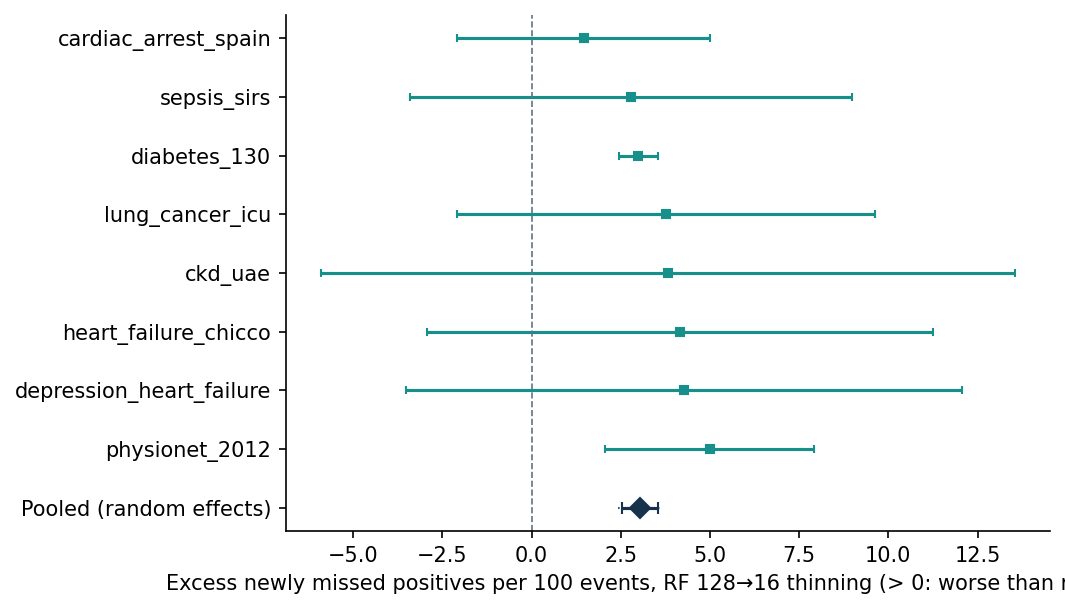

Shareable ZIP (no patient-level data): /content/drive/MyDrive/CHICCO_MEGA_RESEARCH/results/EXCESS_TIERB_DAVIDE_20261110_R3_SHAREABLE.zip


In [17]:
import matplotlib.pyplot as plt
frames = []
for run in OTHER_RUNS:
    f = PROJECT_HOME / 'results' / run / 'SUMMARY_excess_over_retraining.csv'
    if f.exists(): frames.append(pd.read_csv(f).assign(source=run))
    else: print('not found (skipped):', f)
frames.append(pd.read_csv(OUT / 'SUMMARY_excess_over_retraining.csv').assign(source=RUN_NAME))
ALLS = pd.concat(frames).drop_duplicates(['dataset', 'budget', 'family', 'candidate'], keep='last')
ALLS.to_csv(OUT / 'SUMMARY_all_datasets.csv', index=False)

def dersimonian_laird(est, se):
    est, se = np.asarray(est, float), np.asarray(se, float); k = len(est)
    w = 1 / se**2; fe = np.sum(w * est) / np.sum(w); Q = np.sum(w * (est - fe)**2)
    tau2 = max(0.0, (Q - (k - 1)) / (np.sum(w) - np.sum(w**2) / np.sum(w))) if k > 1 else 0.0
    wr = 1 / (se**2 + tau2); mu = np.sum(wr * est) / np.sum(wr); se_mu = np.sqrt(1 / np.sum(wr))
    t = stats.t.ppf(0.975, max(1, k - 2)); pi = (mu - t * np.sqrt(tau2 + se_mu**2), mu + t * np.sqrt(tau2 + se_mu**2))
    i2 = max(0.0, (Q - (k - 1)) / Q) if Q > 0 else 0.0
    return dict(k=k, pooled=mu, ci_low=mu - 1.96 * se_mu, ci_high=mu + 1.96 * se_mu, pi_low=pi[0], pi_high=pi[1], tau2=tau2, I2=i2)

meta_rows = []; fig_data = {}
for cand in ['rf_thinned', 'rf_direct_small', 'gbm_truncated', 'gbm_direct_small']:
    e = ALLS[(ALLS.budget == PRIMARY_BUDGET) & (ALLS.candidate == cand)].dropna(subset=['excess_newly_missed_per100_ci_low'])
    if len(e) < 2: continue
    tq = stats.t.ppf(0.975, e.splits - 1)
    se = (e.excess_newly_missed_per100_ci_high - e.excess_newly_missed_per100_ci_low) / (2 * tq)
    r = dersimonian_laird(e.excess_newly_missed_per100, se); r['candidate'] = cand; meta_rows.append(r)
    fig_data[cand] = (e.assign(se=se), r)
META = pd.DataFrame(meta_rows); META.to_csv(OUT / 'META_ANALYSIS_excess.csv', index=False)
print('RANDOM-EFFECTS META-ANALYSIS · excess newly missed per 100 events · budget', PRIMARY_BUDGET)
display(META[['candidate', 'k', 'pooled', 'ci_low', 'ci_high', 'pi_low', 'pi_high', 'I2']].round(3))

if 'rf_thinned' in fig_data:
    e, r = fig_data['rf_thinned']; e = e.sort_values('excess_newly_missed_per100')
    fig, ax = plt.subplots(figsize=(7.2, 0.32 * len(e) + 1.6), dpi=150); y = np.arange(len(e))[::-1] + 1
    ax.errorbar(e.excess_newly_missed_per100, y, xerr=[e.excess_newly_missed_per100 - e.excess_newly_missed_per100_ci_low,
                e.excess_newly_missed_per100_ci_high - e.excess_newly_missed_per100], fmt='s', color='#178F8A', ms=4, capsize=2)
    ax.errorbar(r['pooled'], 0, xerr=[[r['pooled'] - r['ci_low']], [r['ci_high'] - r['pooled']]], fmt='D', color='#17324D', ms=7, capsize=3)
    ax.plot([r['pi_low'], r['pi_high']], [0, 0], color='#17324D', lw=0.8, ls=':')
    ax.axvline(0, color='#5E7486', ls='--', lw=.8)
    ax.set_yticks(list(y) + [0]); ax.set_yticklabels(list(e.dataset) + ['Pooled (random effects)'])
    ax.set_xlabel('Excess newly missed positives per 100 events, RF 128→16 thinning (> 0: worse than retraining)')
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    fig.tight_layout()
    for ext in ('png', 'pdf'): fig.savefig(OUT / 'figures' / f'fig_meta_rf_thinned.{ext}', dpi=200, facecolor='white')
    plt.show(); plt.close(fig)

share = PROJECT_HOME / 'results' / (RUN_NAME + '_SHAREABLE.zip')
with zipfile.ZipFile(share, 'w', zipfile.ZIP_DEFLATED) as zf:
    for f in ['PROTOCOL.json', 'TARGETS_USED.md', 'SUMMARY_excess_over_retraining.csv', 'SUMMARY_all_datasets.csv', 'META_ANALYSIS_excess.csv',
              'comparisons_per_split.csv', 'metrics_per_split.csv', 'mechanism_per_split.csv', 'model_sizes_first_split.csv']:
        if (OUT / f).exists(): zf.write(OUT / f, arcname=f)
    for f in sorted((OUT / 'figures').glob('*')): zf.write(f, arcname='figures/' + f.name)
(OUT / 'MANIFEST.json').write_text(json.dumps(dict(completed_utc=datetime.now(timezone.utc).isoformat(), config=CONFIG,
        signature=SIGNATURE, data={n: DATA[n][3] for n in DATA}, fetch_status={k: (v if isinstance(v, str) else list(v)) for k, v in fetch_status.items()}), indent=2, default=str))
with zipfile.ZipFile(share, 'a') as zf: zf.write(OUT / 'MANIFEST.json', arcname='MANIFEST.json')
print('Shareable ZIP (no patient-level data):', share)

In [18]:
import pandas as pd
f = DAV / 'lung_cancer_icu' / 'pone.0210951.s006.xlsx'
df = pd.read_excel(f, sheet_name='Sheet2')
cols = [c for c in ['ICU_Death', 'GW_Death', 'Hospital_death', 'Death', 'ICU_mortal30'] if c in df.columns]
print('patients:', len(df))
print(df[cols].apply(pd.to_numeric, errors='coerce').sum())

patients: 264
ICU_Death         121.0
GW_Death           53.0
Hospital_death    160.0
Death             278.0
ICU_mortal30      108.0
dtype: float64
